In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

from f1_stats import (load_gaps, pair_season_table, estimate_tau2, find_file, fit_ratings,
                      predicted_gap, setup_plot_style, TEAM_LINEAGE, REG_CHANGE_SEASONS,
                      BLUE, ORANGE, MUTED)

setup_plot_style()
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

gaps = load_gaps()
ps = pair_season_table(gaps)
usable = ps[ps['usable']]
tau2, _ = estimate_tau2(ps)
quali = pd.read_csv(find_file('qualifying_clean.csv'))
print(f'{len(usable)} usable pair-seasons, tau^2 = {tau2:.4f}')

137 usable pair-seasons, tau^2 = 0.0153


In [2]:
quali['lineage'] = quali['constructorId'].map(TEAM_LINEAGE).fillna(quali['constructorId'])
seasons_of = quali.groupby('driverId')['year'].apply(lambda s: sorted(set(s)))
age_at_start = quali.groupby(['driverId', 'year'])['age'].min()
team_of = quali.groupby(['driverId', 'year'])['lineage'].agg(lambda s: s.mode().iat[0])
seasons_together = gaps.groupby(['A', 'B'])['year'].apply(lambda s: sorted(set(s)))

def experience(driver, s):
    return sum(1 for y in seasons_of[driver] if y < s)

def changed_team(driver, s):
    return int(team_of.get((driver, s - 1)) != team_of.get((driver, s)))

rows = []
for s in range(2015, 2027):
    for r in usable[usable['year'] == s].itertuples():
        # ratings fitted on seasons BEFORE s only, anchored on driver A
        prior, prior_se = predicted_gap(fit_ratings(ps, s, tau2, use_future=False, reference=r.A), r.A, r.B)
        last = usable[(usable['year'] == s - 1) & (usable['A'] == r.A) & (usable['B'] == r.B)]['mean']
        rows.append({
            'year': s, 'team': r.team, 'A': r.A, 'B': r.B, 'y': r.mean,
            'prior': prior, 'prior_se': prior_se,
            'last': last.iat[0] if len(last) else np.nan,
            'age_diff': age_at_start[(r.A, s)] - age_at_start[(r.B, s)],
            'exp_diff': experience(r.A, s) - experience(r.B, s),
            'rookie_diff': int(experience(r.A, s) == 0) - int(experience(r.B, s) == 0),
            'newteam_diff': changed_team(r.A, s) - changed_team(r.B, s),
            'years_together': sum(1 for y in seasons_together.get((r.A, r.B), []) if y < s),
            'reg_change': int(s in REG_CHANGE_SEASONS),
        })

F = pd.DataFrame(rows)
F['has_prior'] = F['prior'].notna().astype(int)
F['has_last'] = F['last'].notna().astype(int)
F['prior_f'] = F['prior'].fillna(0)
F['prior_se_f'] = F['prior_se'].fillna(1.0)
F['last_f'] = F['last'].fillna(F['prior']).fillna(0)

print(f'{len(F)} rows | continuing pairs: {F.has_last.sum()} | new pairs: {(1 - F.has_last).sum()} '
      f'| with a prior estimate: {F.has_prior.sum()}')
F.to_csv('data/ml_features.csv', index=False)
F.head()

126 rows | continuing pairs: 61 | new pairs: 65 | with a prior estimate: 79


,year,team,A,B,y,prior,prior_se,last,age_diff,exp_diff,rookie_diff,newteam_diff,years_together,reg_change,has_prior,has_last,prior_f,prior_se_f,last_f
0,2015,ferrari,kimi-raikkonen,sebastian-vettel,0.339639,NaN,NaN,NaN,7.709788,0,0,-1,0,0,0,0,0.000000,1.000000,0.000000
1,2015,force-india,nico-hulkenberg,sergio-perez,-0.157460,-0.179099,0.175475,-0.179099,2.439425,0,0,0,1,0,1,1,-0.179099,0.175475,-0.179099
2,2015,lotus-f1,pastor-maldonado,romain-grosjean,0.439716,0.309609,0.248300,0.309609,1.106092,0,0,0,1,0,1,1,0.309609,0.248300,0.309609
3,2015,marussia,roberto-merhi,will-stevens,0.539381,NaN,NaN,NaN,0.268309,-1,1,0,0,0,0,0,0.000000,1.000000,0.000000
4,2015,mclaren,fernando-alonso,jenson-button,-0.056426,NaN,NaN,NaN,-1.486653,0,0,1,0,0,0,0,0.000000,1.000000,0.000000


In [3]:
FLIP = ['prior_f', 'last_f', 'age_diff', 'exp_diff', 'rookie_diff', 'newteam_diff']
KEEP = ['has_prior', 'has_last', 'prior_se_f', 'years_together', 'reg_change']
FEATURES = FLIP + KEEP

def mirrored(d):
    m = d.copy()
    m[FLIP] = -m[FLIP]
    m['y'] = -m['y']
    return pd.concat([d, m], ignore_index=True)

MODELS = {
    'Ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=30)),
    'Random forest': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0),
    'Gradient boosting': lambda: GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                                           max_depth=2, subsample=0.8, random_state=0),
}

def walk_forward(seasons):
    """For each season s: train every model on seasons < s, predict s. Returns all predictions."""
    out = []
    for s in seasons:
        train, test = mirrored(F[F['year'] < s]), F[F['year'] == s].copy()
        test['Guess 0'] = 0.0
        test["Last season's gap"] = test['last'].fillna(0)
        test['Statistical prior'] = test['prior'].fillna(0)
        for name, make in MODELS.items():
            model = make().fit(train[FEATURES], train['y'])
            test[name] = model.predict(test[FEATURES])
        test['Hybrid'] = np.where(test['has_last'] == 1, test['last'], test['Random forest'])
        out.append(test)
    return pd.concat(out, ignore_index=True)

CANDIDATES = ['Guess 0', "Last season's gap", 'Statistical prior', 'Ridge', 'Random forest',
              'Gradient boosting', 'Hybrid']

def scores(d):
    rows = []
    for c in CANDIDATES:
        err = d['y'] - d[c]
        picks = d[c] != 0
        rows.append({'method': c, 'MAE': err.abs().mean(), 'RMSE': np.sqrt((err**2).mean()),
                     'direction': (np.sign(d.loc[picks, c]) == np.sign(d.loc[picks, 'y'])).sum() / len(d),
                     'MAE continuing pairs': err[d['has_last'] == 1].abs().mean(),
                     'MAE new pairs': err[d['has_last'] == 0].abs().mean()})
    return pd.DataFrame(rows).set_index('method')

In [4]:
val = walk_forward(range(2016, 2025))
val_scores = scores(val)
print(f'{len(val)} validation pair-seasons')
val_scores.round(3)

95 validation pair-seasons


,MAE,RMSE,direction,MAE continuing pairs,MAE new pairs
method,,,,,
Guess 0,0.277,0.353,0.000,0.242,0.310
Last season's gap,0.232,0.314,0.400,0.153,0.310
Statistical prior,0.247,0.340,0.516,0.150,0.342
Ridge,0.243,0.324,0.653,0.168,0.316
Random forest,0.227,0.299,0.663,0.163,0.290
Gradient boosting,0.250,0.346,0.653,0.137,0.360
Hybrid,0.222,0.296,0.716,0.153,0.290


In [5]:
best = val_scores['MAE'].idxmin()
residuals = val['y'] - val[best]
half_width = np.quantile(residuals.abs(), 0.95)     # 95% prediction interval = prediction ± this
print(f'Chosen method (lowest validation MAE): {best}')
print(f'95% prediction interval: prediction ± {half_width:.2f} percentage points')

Chosen method (lowest validation MAE): Hybrid
95% prediction interval: prediction ± 0.59 percentage points


In [6]:
test = walk_forward([2025, 2026])
test['prediction'] = test[best]
test['inside_95'] = (test['y'] - test['prediction']).abs() <= half_width
err = test['y'] - test['prediction']
print(f"Test pair-seasons: {len(test)}")
print(f"{best}: MAE {err.abs().mean():.3f} | RMSE {np.sqrt((err**2).mean()):.3f} | "
      f"direction {(np.sign(test['prediction']) == np.sign(test['y'])).mean():.0%} | "
      f"coverage of 95% interval {test['inside_95'].mean():.0%}")
scores(test).round(3)

Test pair-seasons: 21
Hybrid: MAE 0.165 | RMSE 0.212 | direction 86% | coverage of 95% interval 100%


,MAE,RMSE,direction,MAE continuing pairs,MAE new pairs
method,,,,,
Guess 0,0.232,0.285,0.000,0.225,0.239
Last season's gap,0.198,0.249,0.429,0.153,0.239
Statistical prior,0.161,0.199,0.619,0.145,0.176
Ridge,0.176,0.215,0.810,0.184,0.169
Random forest,0.168,0.217,0.857,0.160,0.175
Gradient boosting,0.196,0.250,0.810,0.154,0.234
Hybrid,0.165,0.212,0.857,0.153,0.175


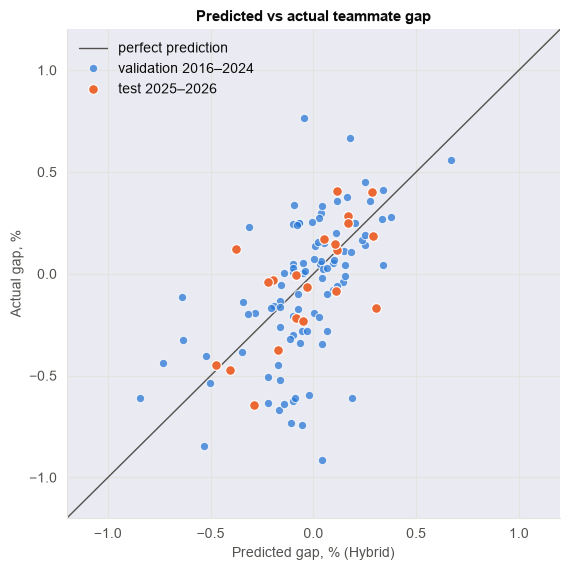

In [7]:
fig, ax = plt.subplots(figsize=(5.8, 5.8))
lim = 1.2
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=1, label='perfect prediction')
ax.plot(val[best], val['y'], 'o', color=BLUE, markersize=6, alpha=0.75,
        markeredgecolor='white', markeredgewidth=0.8, label='validation 2016–2024')
ax.plot(test['prediction'], test['y'], 'o', color=ORANGE, markersize=7,
        markeredgecolor='white', markeredgewidth=0.8, label='test 2025–2026')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(f'Predicted gap, % ({best})')
ax.set_ylabel('Actual gap, %')
ax.set_title('Predicted vs actual teammate gap')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('figures/ml_pred_vs_actual.png', bbox_inches='tight')
plt.show()

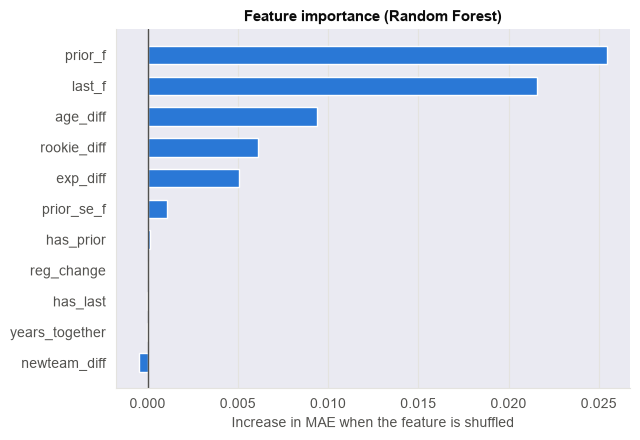

prior_f           0.0254
last_f            0.0216
age_diff          0.0094
rookie_diff       0.0061
exp_diff          0.0051
prior_se_f        0.0011
has_prior         0.0001
reg_change        0.0000
has_last         -0.0000
years_together   -0.0000
newteam_diff     -0.0005
dtype: float64

In [8]:
imp = []
for s in range(2016, 2025):
    train, hold = mirrored(F[F['year'] < s]), F[F['year'] == s]
    model = MODELS['Random forest']().fit(train[FEATURES], train['y'])
    res = permutation_importance(model, hold[FEATURES], hold['y'], n_repeats=10, random_state=0,
                                 scoring='neg_mean_absolute_error')
    imp.append(res.importances_mean)
importance = pd.Series(np.mean(imp, axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Increase in MAE when the feature is shuffled')
ax.set_title('Feature importance (Random Forest)')
fig.tight_layout()
fig.savefig('figures/ml_feature_importance.png', bbox_inches='tight')
plt.show()
importance.sort_values(ascending=False).round(4)

In [9]:
keep = ['year', 'team', 'A', 'B', 'y', 'has_last'] + CANDIDATES
pd.concat([val[keep].assign(split='validation'),
           test[keep + ['inside_95']].assign(split='test')]).to_csv('data/ml_predictions.csv', index=False)
print('saved data/ml_predictions.csv')

saved data/ml_predictions.csv
